# Landau-Lifshitz-Gilbert Dynamics

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dschick/udkm1Dsim/blob/develop/examples/04-magnetization/01-LLG.ipynb)

Here we introduce the magnetization simulations of the **udkm1Dsim** package with the Landau-Lifshitz-Gilbert (LLG) equation, the most basic of the magnetization models.
As an example, we reproduce the laser-induced magnetization precession of a buried Ni layer in Pt-Cu-Ni heterostructures of {cite:t}`jarecki2024`.
Their precession is driven by the demagnetization of the Ni and by its strain, which consists of a quasi-static expansion and of strain pulses, whose round trip through the heterostructure can be resonant with the precession.
An insulating MgO interlayer, which stops the heat transport via electrons, controls these driving mechanisms.

:::{admonition} Reference {cite}`jarecki2024`
:class: seealso
J. Jarecki, M. Mattern, F.-C. Weber, J.-E. Pudell, X.-G. Wang, J.-C. Rojas Sánchez, M. Hehn, A. von Reppert, and M. Bargheer,
*Controlling effective field contributions to laser-induced magnetization precession by heterostructure design*,
[Commun. Phys. 7, 112 (2024)](https://doi.org/10.1038/s42005-024-01602-z)
:::

The {py:class}`LLG <udkm1Dsim.simulations.magnetization.LLG>` class solves the LLG in its Landau-Lifshitz form for the unit vector $\mathbf{n}$ of the magnetization of every layer

\begin{align*}
\frac{d\mathbf{n}}{dt} = \frac{\gamma}{1+\alpha^2}\left(\mathbf{n} \times \mathbf{B}
+ \alpha\, \mathbf{n} \times (\mathbf{n} \times \mathbf{B})\right)
\end{align*}

with the Gilbert damping $\alpha$ {cite:p}`gilbert2004`, the gyromagnetic ratio $\gamma$, which defaults to the one of a free electron $\gamma_e = -1.761\times10^{11}$ rad/(s T), and the effective field $\mathbf{B}$.
The effective field is the sum of

* the external field $\mathbf{B}_\mathrm{ext}$,
* the anisotropy field $\mathbf{B}_\mathrm{A}$,
* the exchange field $\mathbf{B}_\mathrm{ex}$ between neighbouring layers, and
* the magnetoelastic field $\mathbf{B}_\mathrm{me}$ of the strain.

The definitions of these terms are described in the {py:class}`LLG <udkm1Dsim.simulations.magnetization.LLG>` class API documentation.
The amplitude $m$ of the magnetization $\mathbf{m} = m\,\mathbf{n}$ is not a dynamic variable of the LLG but an input.
The [inertial LLG](#example_iLLG) adds the inertia of the magnetization and the [LLB](#example_LLB) also describes the dynamics of the amplitude.

This example is adapted from the examples of [friweber/udkm1Dsim_LLG-LLB](https://github.com/friweber/udkm1Dsim_LLG-LLB) by [@friweber](https://github.com/friweber).

## Setup

Do all necessary imports and settings.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.constants as constants

try:
    import udkm1Dsim as ud
except ImportError:
    %pip install udkm1Dsim
    import udkm1Dsim as ud

from udkm1Dsim.simulations.solvers import mean_field

u = ud.u  # import the pint unit registry from udkm1Dsim
u.setup_matplotlib()  # use matplotlib with pint units

%matplotlib inline

## Structure

Refer to the [structure example](#example_structure) for more details.

The three heterostructures of {cite:t}`jarecki2024` consist of a Pt cap layer, which absorbs most of the pump pulse, a Cu layer, which transports the energy via hot electrons, and a buried 22 nm thick Ni layer on a Ta seed layer and a glass substrate.
They only differ by the position of a 5 nm thick insulating MgO interlayer:

* sample 1: Pt 7 nm / Cu 95 nm / Ni 22 nm / Ta 8 nm / glass
* sample 2: Pt 7 nm / Cu 95 nm / MgO 5 nm / Ni 22 nm / Ta 8 nm / glass
* sample 3: Pt 10 nm / MgO 5 nm / Cu 92 nm / Ni 22 nm / Ta 8 nm / glass

The thermo-elastic parameters are taken from Table 1 of the paper.
The two-temperature model of the metals has the electronic heat capacity $C_e = \gamma_S T_e$ with the Sommerfeld constant $\gamma_S$ and the electronic heat conductivity $\kappa_e = \kappa_e^0 T_e / T_p$.
As **udkm1Dsim** takes the heat capacities per mass, they are divided by the density.
The paper relates the energy density of the electrons and phonons to the stress via the Grüneisen parameters $\Gamma$, which corresponds to the linear thermal expansion coefficients $\alpha = \Gamma C / C_{33}$ of the sub-systems with their heat capacity $C$ per volume and the elastic constant $C_{33} = \rho v_s^2$.
The insulators MgO and glass have no electronic heat conductivity, so the electrons cannot cross them.

In [2]:
# Pt cap layer, which absorbs most of the pump pulse
rho = 21450  # density [kg/m³]
v_s = 4.2  # sound velocity [nm/ps]
gamma_S = 730  # Sommerfeld constant [J/(m³K²)]
C_ph = 2.85e6  # heat capacity of the phonons [J/(m³K)]
kappa_el_0, kappa_ph = 66, 5.0  # heat conductivities [W/(m K)]
g = 3.75e17  # electron-phonon coupling [W/(m³K)]
Gamma_el, Gamma_ph = 1.2, 2.6  # Grüneisen parameters
C_33 = rho * (v_s * 1e3) ** 2  # elastic constant [J/m³]

layer_Pt = ud.Layer(
    "Pt",
    "Platinum",
    structural=ud.StructuralParameters(thickness=1 * u.nm, density=rho * u.kg / u.m**3),
    # two-temperature model
    thermal=ud.ThermalParameters(
        heat_capacity=[f"{gamma_S / rho:g}*T", C_ph / rho * u.J / u.kg / u.K],
        therm_cond=[f"{kappa_el_0:g}*T_0/T_1", kappa_ph * u.W / (u.m * u.K)],
        sub_system_coupling=[f"-{g:g}*(T_0-T_1)", f"{g:g}*(T_0-T_1)"],
        lin_therm_exp=[f"{Gamma_el * gamma_S / C_33:g}*T", Gamma_ph * C_ph / C_33],
        sub_system_labels=["e", "p"],  # electrons and phonons
    ),
    elastic=ud.ElasticParameters(sound_vel=v_s * u.nm / u.ps),
    optical=ud.OpticalParameters(opt_ref_index=0.576 + 8.078j),
)
layer_Pt.thermal

Thermal Parameters
╔═════════════════════╦══════════╦══════════════════════════════╦════════╗
║ Parameter           ║  Symbol  ║                        Value ║ Unit   ║
╠═════════════════════╬══════════╬══════════════════════════════╬════════╣
║ therm_cond          ║    κₑ    ║                     66·Tₑ/Tₚ ║ W/K/m  ║
║                     ║    κₚ    ║                            5 ║        ║
╠═════════════════════╬══════════╬══════════════════════════════╬════════╣
║ heat_capacity       ║    cₑ    ║                   0.03403·Tₑ ║ J/K/kg ║
║                     ║    cₚ    ║                        132.9 ║        ║
╠═════════════════════╬══════════╬══════════════════════════════╬════════╣
║ lin_therm_exp       ║    αₑ    ║                2.315×10⁻⁹·Tₑ ║        ║
║                     ║    αₚ    ║                   1.958×10⁻⁵ ║        ║
╠═════════════════════╬══════════╬══════════════════════════════╬════════╣
║ sub_system_coupling ║    Gₑ    ║ −3.75×10¹⁷·Tₑ + 3.75×10¹⁷·Tₚ ║ W/m³   ║
║                     ║    Gₚ    ║  3.75×10¹⁷·Tₑ − 3.75×10¹⁷·Tₚ ║        ║
╠═════════════════════╬══════════╬══════════════════════════════╬════════╣
║ deb_wal_fac         ║  ⟨u²⟩ₑ   ║                            0 ║ m²     ║
╠═════════════════════╬══════════╬══════════════════════════════╬════════╣
║ num_sub_systems     ║    N     ║                            2 ║        ║
╚═════════════════════╩══════════╩══════════════════════════════╩════════╝

In [3]:
# similar to the Pt layer
rho = 8960
v_s = 5.2
gamma_S = 100
C_ph = 3.44e6
kappa_el_0, kappa_ph = 396, 5.0
g = 0.95e17
Gamma_el, Gamma_ph = 0.9, 2.0
C_33 = rho * (v_s * 1e3) ** 2

layer_Cu = ud.Layer(
    "Cu",
    "Copper",
    structural=ud.StructuralParameters(thickness=1 * u.nm, density=rho * u.kg / u.m**3),
    thermal=ud.ThermalParameters(
        heat_capacity=[f"{gamma_S / rho:g}*T", C_ph / rho * u.J / u.kg / u.K],
        therm_cond=[f"{kappa_el_0:g}*T_0/T_1", kappa_ph * u.W / (u.m * u.K)],
        sub_system_coupling=[f"-{g:g}*(T_0-T_1)", f"{g:g}*(T_0-T_1)"],
        lin_therm_exp=[f"{Gamma_el * gamma_S / C_33:g}*T", Gamma_ph * C_ph / C_33],
        sub_system_labels=["e", "p"],
    ),
    elastic=ud.ElasticParameters(sound_vel=v_s * u.nm / u.ps),
    optical=ud.OpticalParameters(opt_ref_index=0.105 + 5.141j),
)

In [4]:
# similar to the Pt layer
rho = 16680
v_s = 4.2
gamma_S = 380
C_ph = 2.33e6
kappa_el_0, kappa_ph = 52, 5.0
g = 1.0e17
Gamma_el, Gamma_ph = 1.3, 1.6
C_33 = rho * (v_s * 1e3) ** 2

layer_Ta = ud.Layer(
    "Ta",
    "Tantalum",
    structural=ud.StructuralParameters(thickness=1 * u.nm, density=rho * u.kg / u.m**3),
    thermal=ud.ThermalParameters(
        heat_capacity=[f"{gamma_S / rho:g}*T", C_ph / rho * u.J / u.kg / u.K],
        therm_cond=[f"{kappa_el_0:g}*T_0/T_1", kappa_ph * u.W / (u.m * u.K)],
        sub_system_coupling=[f"-{g:g}*(T_0-T_1)", f"{g:g}*(T_0-T_1)"],
        lin_therm_exp=[f"{Gamma_el * gamma_S / C_33:g}*T", Gamma_ph * C_ph / C_33],
        sub_system_labels=["e", "p"],
    ),
    elastic=ud.ElasticParameters(sound_vel=v_s * u.nm / u.ps),
    optical=ud.OpticalParameters(opt_ref_index=0.992 + 7.293j),
)

In [5]:
# the insulating MgO interlayer has no electronic heat conductivity,
# the reduced heat conductivity of the phonons accounts for the interface resistance
rho = 3580
v_s = 9.1
C_ph = 3.32e6
Gamma_ph = 1.7
C_33 = rho * (v_s * 1e3) ** 2

layer_MgO = ud.Layer(
    "MgO",
    "Magnesium Oxide",
    structural=ud.StructuralParameters(thickness=1 * u.nm, density=rho * u.kg / u.m**3),
    thermal=ud.ThermalParameters(
        heat_capacity=[1 * u.J / u.kg / u.K, C_ph / rho * u.J / u.kg / u.K],
        therm_cond=[0, 2.5 * u.W / (u.m * u.K)],
        sub_system_coupling=[0, 0],
        lin_therm_exp=[0, Gamma_ph * C_ph / C_33],
        sub_system_labels=["e", "p"],
    ),
    elastic=ud.ElasticParameters(sound_vel=v_s * u.nm / u.ps),
    optical=ud.OpticalParameters(opt_ref_index=1.728 + 0j),
)

# similar to the MgO layer, but with 10 nm thick layers for the thick substrate
rho = 2540
v_s = 5.7
C_ph = 1.80e6
Gamma_ph = 0.3
C_33 = rho * (v_s * 1e3) ** 2

layer_glass = ud.Layer(
    "glass",
    "Glass",
    structural=ud.StructuralParameters(thickness=10 * u.nm, density=rho * u.kg / u.m**3),
    thermal=ud.ThermalParameters(
        heat_capacity=[1 * u.J / u.kg / u.K, C_ph / rho * u.J / u.kg / u.K],
        therm_cond=[0, 1.0 * u.W / (u.m * u.K)],
        sub_system_coupling=[0, 0],
        lin_therm_exp=[0, Gamma_ph * C_ph / C_33],
        sub_system_labels=["e", "p"],
    ),
    elastic=ud.ElasticParameters(sound_vel=v_s * u.nm / u.ps),
    optical=ud.OpticalParameters(opt_ref_index=1.56 + 0j),
)

The Ni layer is the only magnetic layer.
Solving the LLG requires the following parameters of the {py:class}`magnetic <udkm1Dsim.structures.parameter_groups.MagneticParameters>` parameter group of the according {py:class}`Layer <udkm1Dsim.structures.layers.Layer>` objects:

* `mag_saturation` $M_s$ - saturation magnetization at 0 K, layers with $M_s = 0$ are not magnetic
* `gilbert_damping` $\alpha$ - Gilbert damping
* `gyromagnetic_ratio` $\gamma$ - gyromagnetic ratio, here $\gamma/2\pi = -30.8$ GHz/T as measured for the Ni films by ferromagnetic resonance
* `anisotropy` $K$ - vector of the anisotropy $[K_x, K_y, K_z]$ of easy ($K > 0$) and hard ($K < 0$) axes along the coordinate axes, here only the shape anisotropy $K_z = -\mu_0 M_s^2/2$ of a thin film with its normal along $z$
* `aniso_exponent` $\beta$ - exponent of the temperature dependence $K(m) = K m^\beta$, i.e. $\beta = 2$ for the shape anisotropy
* `exch_stiffness` $A_\mathrm{ex}$ - exchange stiffness between neighbouring layers
* `magnetoelastic_coupling` $B_1$ - magnetoelastic coupling of the out-of-plane strain
* `eff_spin` $S$, `curie_temp` $T_\mathrm{C}$, `mag_moment` $\mu$ - effective spin, Curie temperature, and atomic magnetic moment for the mean-field magnetization, if the amplitude is given by a temperature
* `magnetization` - the initial magnetization, here along $x$

The paper gives the saturation magnetization $M_s = 4.9\times10^5$ A/m at room temperature, i.e. a demagnetizing field of $\mu_0 M_s = 620$ mT, which we scale to 0 K with the mean-field magnetization of 300 K. The magnetoelastic coupling $b_1 = -8.2\times10^6$ J/m³ of the paper corresponds to $B_1 = +8.2\times10^6$ J/m³ in the sign convention of **udkm1Dsim**, see {py:func}`magnetoelastic_field <udkm1Dsim.simulations.solvers.magnetization_scipy.magnetoelastic_field>`, so that an expansion pulls the magnetization towards the film plane, as observed in the paper.
The Gilbert damping is not given in the paper and we assume $\alpha = 0.03$.

In [6]:
# similar to the Pt layer
rho = 8910
v_s = 6.3
gamma_S = 1060
C_ph = 3.94e6
kappa_el_0, kappa_ph = 81.4, 9.6
g = 3.6e17
Gamma_el, Gamma_ph = 1.4, 1.8
C_33 = rho * (v_s * 1e3) ** 2

# saturation magnetization at room temperature and its mean-field scaling to 0 K
M_s_300 = 4.9e5  # A/m
m_300 = mean_field.mean_field_magnetization(300 / 630, 0.5)
mu_0 = constants.mu_0

layer_Ni = ud.Layer(
    "Ni",
    "Nickel",
    structural=ud.StructuralParameters(thickness=1 * u.nm, density=rho * u.kg / u.m**3),
    thermal=ud.ThermalParameters(
        heat_capacity=[f"{gamma_S / rho:g}*T", C_ph / rho * u.J / u.kg / u.K],
        therm_cond=[f"{kappa_el_0:g}*T_0/T_1", kappa_ph * u.W / (u.m * u.K)],
        sub_system_coupling=[f"-{g:g}*(T_0-T_1)", f"{g:g}*(T_0-T_1)"],
        lin_therm_exp=[f"{Gamma_el * gamma_S / C_33:g}*T", Gamma_ph * C_ph / C_33],
        sub_system_labels=["e", "p"],
    ),
    elastic=ud.ElasticParameters(sound_vel=v_s * u.nm / u.ps),
    optical=ud.OpticalParameters(opt_ref_index=2.322 + 8.882j),
    # LLG parameters
    magnetic=ud.MagneticParameters(
        mag_saturation=M_s_300 / m_300 * u.J / u.T / u.m**3,
        gilbert_damping=0.03,
        gyromagnetic_ratio=-2 * np.pi * 30.8e9 * u.rad / u.s / u.T,
        anisotropy=[0, 0, -mu_0 * (M_s_300 / m_300) ** 2 / 2] * u.J / u.m**3,
        aniso_exponent=2,
        exch_stiffness=1e-11 * u.J / u.m,
        magnetoelastic_coupling=8.2e6 * u.J / u.m**3,
        eff_spin=0.5,
        curie_temp=630 * u.K,
        mag_moment=0.62 * u.bohr_magneton,
        magnetization=(1, 0, 0),
    ),
)
print(f"mean-field magnetization at 300 K: {m_300:.3f}")
layer_Ni.magnetic

mean-field magnetization at 300 K: 0.966


Parameter,Symbol,Value,Unit
eff_spin,S,0.5,
curie_temp,TC,630,K
mf_exch_coupling,J,8.698×10−21,kg m2/s2
lamda,λ,0,
mag_moment,μ,5.75×10−24,A m2
aniso_exponent,β,2,
anisotropy,K,"[0, 0, −1.617×105]",J/m3
exch_stiffness,Aex,"[1×10−11, 1×10−11, 1×10−11]",J/m
mag_saturation,Ms,5.073×105,J/(m3 T)
magnetization,r,1,


In [7]:
S_1 = ud.Structure("sample 1")
S_1.add_sub_structure(layer_Pt, 7)
S_1.add_sub_structure(layer_Cu, 95)
S_1.add_sub_structure(layer_Ni, 22)
S_1.add_sub_structure(layer_Ta, 8)
S_1.add_sub_structure(layer_glass, 200)

S_2 = ud.Structure("sample 2")
S_2.add_sub_structure(layer_Pt, 7)
S_2.add_sub_structure(layer_Cu, 95)
S_2.add_sub_structure(layer_MgO, 5)
S_2.add_sub_structure(layer_Ni, 22)
S_2.add_sub_structure(layer_Ta, 8)
S_2.add_sub_structure(layer_glass, 200)

S_3 = ud.Structure("sample 3")
S_3.add_sub_structure(layer_Pt, 10)
S_3.add_sub_structure(layer_MgO, 5)
S_3.add_sub_structure(layer_Cu, 92)
S_3.add_sub_structure(layer_Ni, 22)
S_3.add_sub_structure(layer_Ta, 8)
S_3.add_sub_structure(layer_glass, 200)

structures = {"sample 1": S_1, "sample 2": S_2, "sample 3": S_3}
# color code of the paper
colors = {"sample 1": "tab:red", "sample 2": "tab:blue", "sample 3": "goldenrod"}
for S in structures.values():
    # add semi-infinite, static substrate
    S.add_substrate(layer_glass)

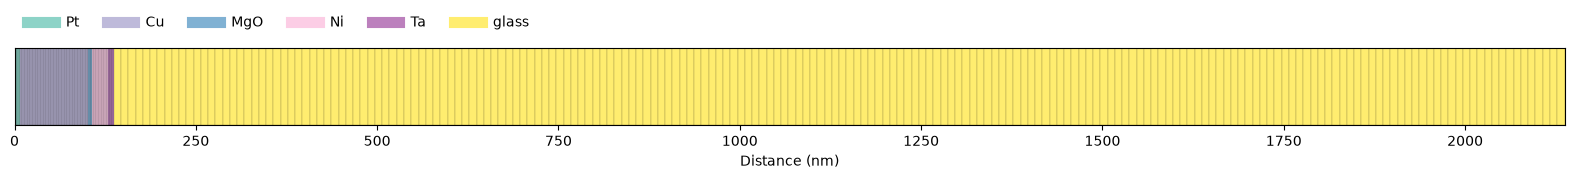

In [8]:
S_2.visualize()

## Initialize Heat and the Excitation

Refer to the [excitation & NTM example](#example_excitation_NTM) for more details.

As in the experiment, the samples are excited from the Pt side by a 100 fs pump pulse at 800 nm under normal incidence with a fluence of 7.5 mJ/cm².
The glass substrate is simulated for 2 µm, so that the strain pulses reflected at its bottom do not return within the delay range.

In [9]:
# temporal grid
delays = np.r_[-20:600:0.5] * u.ps

temp_maps = {}
delta_temp_maps = {}
for name, S in structures.items():
    h = ud.Heat(S, True)
    h.save_data = False
    h.disp_messages = False
    h.heat_diffusion = True
    h.boundary_conditions = {"top_type": "isolator", "bottom_type": "isolator"}
    h.excitation = {
        "fluence": [7.5] * u.mJ / u.cm**2,
        "delay_pump": [0] * u.ps,
        "pulse_width": [0.1] * u.ps,
        "multilayer_absorption": True,
        "wavelength": 800 * u.nm,
        "theta": 90 * u.deg,
    }
    temp_maps[name], delta_temp_maps[name] = h.get_temp_map(delays, 300 * u.K)
h

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

parameter,value
force recalc,True
cache directory,./
display messages,False
save data,False
progress bar,True
excitation fluence,[7.5] mJ/cm²
excitation delay,[0] ps
excitation pulse length,[0.1] ps
excitation wavelength,800 nm
excitation theta,90 deg


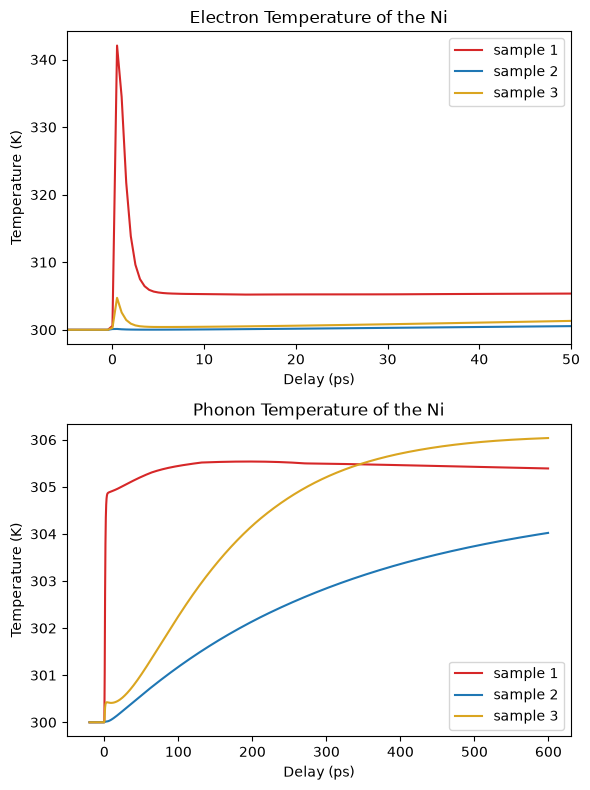

In [10]:
plt.figure(figsize=[6, 8])
for name, S in structures.items():
    select_Ni = S.get_all_positions_per_unique_layer()["Ni"]
    plt.subplot(2, 1, 1)
    plt.plot(
        delays, np.mean(temp_maps[name][:, select_Ni, 0], axis=1), color=colors[name], label=name
    )
    plt.subplot(2, 1, 2)
    plt.plot(
        delays, np.mean(temp_maps[name][:, select_Ni, 1], axis=1), color=colors[name], label=name
    )

plt.subplot(2, 1, 1)
plt.xlim(-5, 50)
plt.xlabel("Delay (ps)")
plt.ylabel("Temperature (K)")
plt.legend()
plt.title("Electron Temperature of the Ni")

plt.subplot(2, 1, 2)
plt.xlabel("Delay (ps)")
plt.ylabel("Temperature (K)")
plt.legend()
plt.title("Phonon Temperature of the Ni")

plt.tight_layout()
plt.show()

Without MgO interlayer, the hot electrons transport the energy through the Cu into the Ni within a picosecond, where the strong electron-phonon coupling heats the phonons.
The MgO interlayer in front of the Ni (sample 2) or the Cu (sample 3) blocks this electronic heat transport, so that the Ni is only slowly heated by the phonons.

## Strain

Refer to the [strain pulses example](#example_strain_pulses) for more details.

The {py:class}`PhononNum <udkm1Dsim.simulations.phonons.PhononNum>` class calculates the strain of the heterostructures, which is the superposition of the quasi-static expansion of the heated layers and of the strain pulses launched at their interfaces.

In [11]:
strain_maps = {}
for name, S in structures.items():
    p = ud.PhononNum(S, True)
    p.save_data = False
    p.disp_messages = False
    strain_maps[name] = p.get_strain_map(delays, temp_maps[name], delta_temp_maps[name])

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

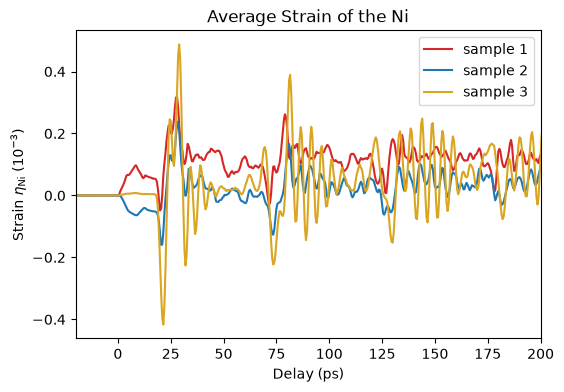

In [12]:
plt.figure(figsize=[6, 4])
for name, S in structures.items():
    select_Ni = S.get_all_positions_per_unique_layer()["Ni"]
    plt.plot(
        delays,
        1e3 * np.mean(strain_maps[name][:, select_Ni], axis=1),
        color=colors[name],
        label=name,
    )
plt.xlim(-20, 200)
plt.xlabel("Delay (ps)")
plt.ylabel(r"Strain $\eta_\mathrm{Ni}$ ($10^{-3}$)")
plt.legend()
plt.title("Average Strain of the Ni")
plt.show()

In sample 1, the rapidly heated Ni expands immediately.
In sample 2, the expansion of the rapidly heated Cu compresses the Ni, and in sample 3 the Ni remains unstrained until the strain pulse launched by the Pt arrives after about 20 ps.
The strain pulses then echo through the heterostructure and periodically strain the Ni.

## Landau-Lifshitz-Gilbert Simulations

The {py:class}`LLG <udkm1Dsim.simulations.magnetization.LLG>` class requires a {py:class}`Structure <udkm1Dsim.structures.structure.Structure>` object and a boolean `force_recalc` in order to overwrite previous simulation results.

These results are saved in the `cache_dir` when `save_data` is enabled.
Printing simulation messages can be en-/disabled using `disp_messages` and progress bars can be enabled using the boolean switch `progress_bar`.

The `ode_options` are handed to `scipy.integrate.solve_ivp`.
Its default `LSODA` method switches automatically between a stiff and a non-stiff integrator, which is required e.g. for the [inertial LLG](#example_iLLG) and the [LLB](#example_LLB).
The LLG of the Ni layer is not stiff, so that the explicit `RK45` method is faster here.

In [13]:
llg = ud.LLG(S_1, True)

llg.save_data = False
llg.disp_messages = True
llg.progress_bar = False
llg.ode_options["method"] = "RK45"

llg

Landau-Lifshitz-Gilbert Magnetization Dynamics simulation properties:

========================  =======
               parameter  value
========================  =======
            force recalc  True
         cache directory  ./
        display messages  True
               save data  False
            progress bar  False
  temperature sub-system  0
magnetization sub-system
========================  =======

This is the current structure for the simulations:

Structure properties:

Name   : sample 1
Thickness : 2132 nm
----
7 times Platinum: 7 nm
95 times Copper: 95 nm
22 times Nickel: 22 nm
8 times Tantalum: 8 nm
200 times Glass: 2000 nm
----
Superstrate (semi-infinite):
----
1 times vacuum: 1 nm
----
Substrate (semi-infinite):
----
1 times Glass: 10 nm

### Precession at a Constant Amplitude

In order to run the LLG simulation, an initial magnetization `init_mag` as well as an external magnetic field `B_ext` can be provided.
While `B_ext` is provided in cartesian coordinates $[B_x, B_y, B_z]$ in tesla, the initial magnetization is given in polar coordinates $[r, \phi, \gamma]$ in units of [none, rad, rad], with the angle $\phi$ from the $z$-axis and $\gamma$ in the $xy$-plane from the $x$-axis.
It is given either as single vector for all layers or as one vector per layer.
Without a `temp_map` or `mag_amplitude_map`, the amplitude of the LLG is the one of `init_mag`.

As in the experiment, the external field of 390 mT is applied at an angle $\xi$ from the film normal, here $\xi = 47°$.
We start the magnetization along $x$ in the film plane, with the amplitude of 300 K.

:::{note}
The resulting `magnetization_map` is returned in **polar coordinates**.
:::

In [14]:
B_0 = 0.39  # strength of the external field [T]
xi = np.radians(47)
B_ext = B_0 * np.array([np.sin(xi), 0, np.cos(xi)])
init_mag = np.array([m_300, np.pi / 2, 0])
delays_free = np.r_[0:1000:0.5] * u.ps

magnetization_map = llg.get_magnetization_map(delays_free, init_mag=init_mag, B_ext=B_ext)

Calculating _magnetization_map_ ...


Elapsed time for _LLG_: 7.560627 s
Elapsed time for _magnetization_map_: 7.563781 s


The {py:mod}`helpers <udkm1Dsim.helpers>` modules provides functions to convert the result also into cartesian coordinates:

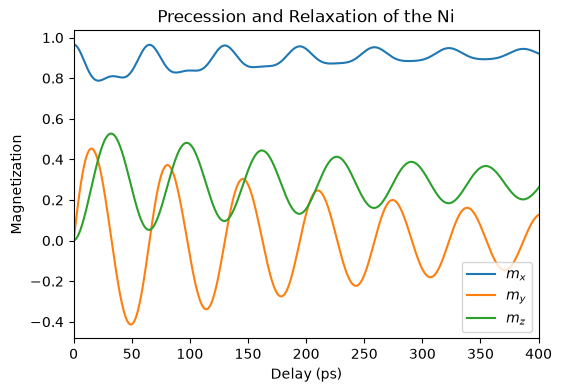

In [15]:
magnetization_map_xyz = ud.helpers.convert_polar_to_cartesian(magnetization_map)
select_Ni = S_1.get_all_positions_per_unique_layer()["Ni"]
m_xyz = np.mean(magnetization_map_xyz[:, select_Ni, :], axis=1)

plt.figure(figsize=[6, 4])
plt.plot(delays_free, m_xyz[:, 0], label="$m_x$")
plt.plot(delays_free, m_xyz[:, 1], label="$m_y$")
plt.plot(delays_free, m_xyz[:, 2], label="$m_z$")
plt.xlim(0, 400)
plt.xlabel("Delay (ps)")
plt.ylabel("Magnetization")
plt.legend()
plt.title("Precession and Relaxation of the Ni")
plt.show()

The magnetization precesses around the effective field and relaxes towards its equilibrium.
The frequency of small precessions around the equilibrium is given by the Smit-Beljers formula {cite:p}`smit1955` from the second derivatives of the energy per magnetic moment, which is the generalization of the Kittel formula {cite:p}`kittel1948`.
In the $xz$-plane of the field, the energy reads with the polar angle $\theta$ of the magnetization from $z$

\begin{align*}
F(\theta) = -B_\mathrm{ext}\left(\sin\xi \sin\theta + \cos\xi \cos\theta\right)
+ \frac{\mu_0 M_s m}{2} \cos^2\theta
\end{align*}

and its second derivatives at the equilibrium $F_{\theta\theta} = B_\mathrm{ext}\cos(\theta - \xi) - \mu_0 M_s m \cos 2\theta$ and $F_{\varphi\varphi} = B_\mathrm{ext}\sin\xi\sin\theta$ give the frequency

\begin{align*}
f = \frac{|\gamma|}{2\pi(1+\alpha^2)}\frac{\sqrt{F_{\theta\theta} F_{\varphi\varphi}}}{\sin\theta}.
\end{align*}

Since the field is below the saturation field of 620 mT, the magnetization is tilted between the field and the film plane, its easy plane.

In [16]:
gamma = abs(layer_Ni.gyromagnetic_ratio.to("rad/(s*T)").magnitude)
alpha = layer_Ni.gilbert_damping.magnitude
B_d = mu_0 * M_s_300  # demagnetizing field at 300 K [T]
theta = np.linspace(0, np.pi, 100001)  # polar angle from z

xi_theory = np.radians(np.r_[1:90:1])
theta_eq = np.zeros(len(xi_theory))
f_smit_beljers = np.zeros(len(xi_theory))
for i, xi_i in enumerate(xi_theory):
    # the equilibrium is the minimum of the energy
    F = -B_0 * (np.sin(xi_i) * np.sin(theta) + np.cos(xi_i) * np.cos(theta))
    F += B_d / 2 * np.cos(theta) ** 2
    theta_0 = theta[np.argmin(F)]
    F_tt = B_0 * np.cos(theta_0 - xi_i) - B_d * np.cos(2 * theta_0)
    F_pp = B_0 * np.sin(xi_i) * np.sin(theta_0)
    theta_eq[i] = theta_0
    f_smit_beljers[i] = (
        gamma / (2 * np.pi * (1 + alpha**2)) * np.sqrt(F_tt * F_pp) / np.sin(theta_0)
    )

i_47 = np.argmin(np.abs(xi_theory - xi))
print(f"equilibrium at 47°: {np.degrees(theta_eq[i_47]):.1f}° from the film normal")
print(f"Smit-Beljers frequency at 47°: {f_smit_beljers[i_47] * 1e-9:.2f} GHz")

# spectrum of the simulated precession
t = delays_free.to("s").magnitude
freqs = np.fft.rfftfreq(8 * len(t), t[1] - t[0])
spectrum = np.abs(
    np.fft.rfft((m_xyz[:, 1] - np.mean(m_xyz[:, 1])) * np.hanning(len(t)), 8 * len(t))
)
print(f"simulated frequency: {freqs[np.argmax(spectrum)] * 1e-9:.2f} GHz")

equilibrium at 47°: 73.1° from the film normal
Smit-Beljers frequency at 47°: 15.60 GHz
simulated frequency: 15.62 GHz


The simulated precession is slightly slower than the Smit-Beljers frequency, as it starts with a large angle from the equilibrium, while the formula holds for small precessions.

### Equilibrium Magnetization

Before an excitation, the magnetization typically rests in its equilibrium of the external field, the anisotropy, the exchange, and the strain.
Instead of simulating the precession for a long time until it has relaxed, {py:meth}`get_equilibrium_magnetization <udkm1Dsim.simulations.magnetization.Magnetization.get_equilibrium_magnetization>` relaxes the directions of the initial magnetization by an overdamped flow without precession into the nearest equilibrium.
It returns the polar magnetization of all layers and sublattices $L \times P \times 3$, which can be used as `init_mag`.
The same is done by the option `equilibrate=True` of `get_magnetization_map` for the inputs at the first delay.

(332, 1, 3)


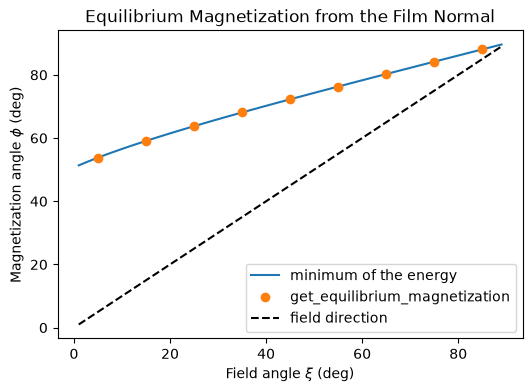

In [17]:
llg.disp_messages = False  # no messages for the scan
xi_scan = np.radians(np.r_[5:90:10])
phi_eq = np.zeros(len(xi_scan))
for i, xi_i in enumerate(xi_scan):
    B_ext_i = B_0 * np.array([np.sin(xi_i), 0, np.cos(xi_i)])
    equilibrium = llg.get_equilibrium_magnetization(B_ext=B_ext_i, init_mag=init_mag)
    phi_eq[i] = equilibrium[select_Ni[0], 0, 1]
print(equilibrium.shape)

plt.figure(figsize=[6, 4])
plt.plot(np.degrees(xi_theory), np.degrees(theta_eq), label="minimum of the energy")
plt.plot(np.degrees(xi_scan), np.degrees(phi_eq), "o", label="get_equilibrium_magnetization")
plt.plot(np.degrees(xi_theory), np.degrees(xi_theory), "k--", label="field direction")
plt.xlabel(r"Field angle $\xi$ (deg)")
plt.ylabel(r"Magnetization angle $\phi$ (deg)")
plt.legend()
plt.title("Equilibrium Magnetization from the Film Normal")
plt.show()

### Magnetization Amplitude from the Temperature

With a `temp_map`, the amplitude of the LLG is the mean-field magnetization $m(t) = m_\mathrm{eq}(T(t))$ of the temperature of the sub-system `temp_sub_system`, see {py:meth}`get_mean_field_mag_map <udkm1Dsim.simulations.magnetization.Magnetization.get_mean_field_mag_map>`.
Following the paper, which uses the static magnetization of the phonon temperature, we select the phonons.
This *adiabatic limit* assumes that the magnetization follows the temperature instantaneously, otherwise the [LLB](#example_LLB) is required.

As the shape anisotropy scales with $m^{\beta-1}$, the drop of the amplitude reduces the demagnetizing field and tilts the effective field towards the film normal, which drives a precession {cite:p}`vankampen2002`.
The magnetization starts in the equilibrium of the first delay, so we take the `delays` of the heat simulations starting before the excitation.
We look at sample 1 at a field angle of $\xi = 5°$, at which the demagnetization of the Ni drives the precession most efficiently.

In [18]:
llg.temp_sub_system = 1  # the phonons
xi = np.radians(5)
B_ext = B_0 * np.array([np.sin(xi), 0, np.cos(xi)])

magnetization_map_temp = llg.get_magnetization_map(
    delays, temp_map=temp_maps["sample 1"], init_mag=init_mag, B_ext=B_ext, equilibrate=True
)

Instead of the mean field, the amplitude can also be given directly as `mag_amplitude_map` of the dimension $M \times L$ for all layers, e.g. from a phenomenological model, a measurement, or the microscopic three-temperature model of the [M3TM example](#example_m3tm).
Here we give the mean-field magnetization of the phonon temperature directly, which reproduces the simulation above.

In [19]:
mag_amplitude_map = llg.get_mean_field_mag_map(temp_maps["sample 1"][:, :, 1])
print(mag_amplitude_map.shape)

magnetization_map_amp = llg.get_magnetization_map(
    delays, mag_amplitude_map=mag_amplitude_map, init_mag=init_mag, B_ext=B_ext, equilibrate=True
)
print(f"largest deviation: {np.max(np.abs(magnetization_map_amp - magnetization_map_temp)):.1e}")

(1240, 332)


largest deviation: 0.0e+00


### Strain and Magnetoelastic Coupling

The out-of-plane strain $\eta$ enters the LLG via the `strain_map` as magnetoelastic field $\mathbf{B}_\mathrm{me} = -\frac{2 B_1 \eta}{M_s} m^{\beta-2} m_z \hat{\mathbf{z}}$, see {py:func}`magnetoelastic_field <udkm1Dsim.simulations.solvers.magnetization_scipy.magnetoelastic_field>`, i.e. as additional anisotropy along $z$, which drives magnetoacoustic precession {cite:p}`kim2012`.
We compare the change of the out-of-plane magnetization $\Delta m_z$ of the Ni due to the demagnetization alone, due to the strain alone, i.e. at a constant amplitude, and due to both together.

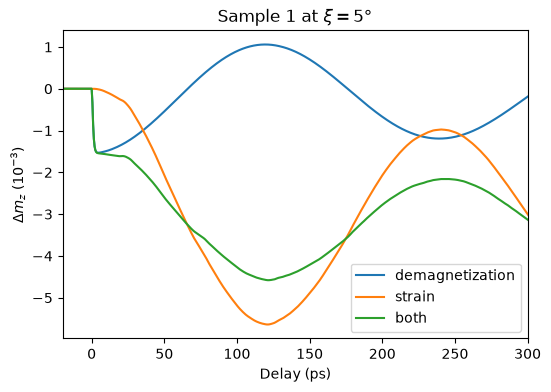

In [20]:
magnetization_map_strain = llg.get_magnetization_map(
    delays, strain_map=strain_maps["sample 1"], init_mag=init_mag, B_ext=B_ext, equilibrate=True
)
magnetization_map_both = llg.get_magnetization_map(
    delays,
    temp_map=temp_maps["sample 1"],
    strain_map=strain_maps["sample 1"],
    init_mag=init_mag,
    B_ext=B_ext,
    equilibrate=True,
)

plt.figure(figsize=[6, 4])
for label, result in [
    ("demagnetization", magnetization_map_temp),
    ("strain", magnetization_map_strain),
    ("both", magnetization_map_both),
]:
    m_z = np.mean(ud.helpers.convert_polar_to_cartesian(result)[:, select_Ni, 2], axis=1)
    plt.plot(delays, 1e3 * (m_z - m_z[0]), label=label)
plt.xlim(-20, 300)
plt.xlabel("Delay (ps)")
plt.ylabel(r"$\Delta m_z$ ($10^{-3}$)")
plt.legend()
plt.title(r"Sample 1 at $\xi = 5°$")
plt.show()

The demagnetization reduces $m_z$ within picoseconds and tilts the effective field towards the film normal, whereas the expansion of the Ni tilts it towards the film plane.
Both drive the precession with opposite phase, and the quasi-static strain dominates, as observed in the paper.

## Heterostructure-Dependent Precession

Now we compare the three heterostructures at the field angles of Fig. 2(c) and (d) of the paper, $\xi = 5°$ and $\xi = 47°$.
Every structure requires its own {py:class}`LLG <udkm1Dsim.simulations.magnetization.LLG>` object.

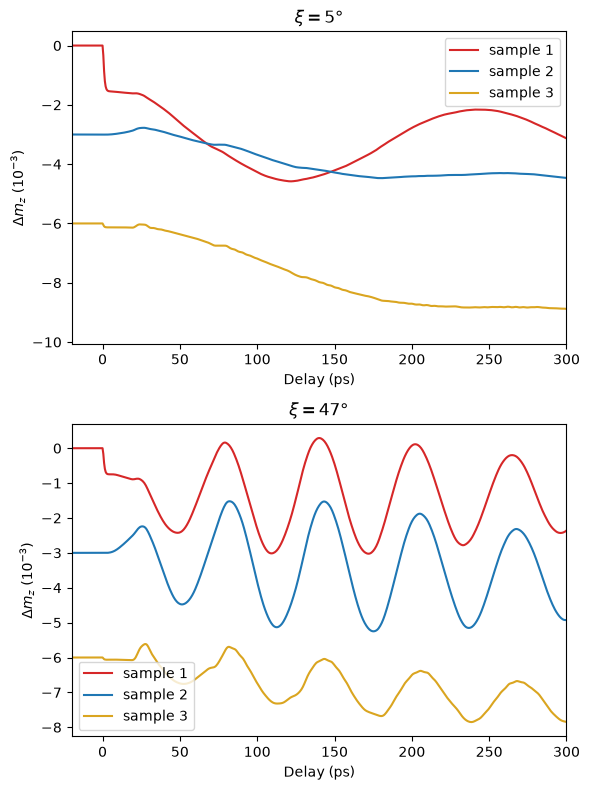

In [21]:
llgs = {}
for name, S in structures.items():
    llgs[name] = ud.LLG(S, True)
    llgs[name].save_data = False
    llgs[name].disp_messages = False
    llgs[name].progress_bar = False
    llgs[name].ode_options["method"] = "RK45"
    llgs[name].temp_sub_system = 1

plt.figure(figsize=[6, 8])
for k, xi_deg in enumerate([5, 47]):
    xi = np.radians(xi_deg)
    B_ext = B_0 * np.array([np.sin(xi), 0, np.cos(xi)])
    plt.subplot(2, 1, k + 1)
    for i, (name, S) in enumerate(structures.items()):
        select_Ni = S.get_all_positions_per_unique_layer()["Ni"]
        magnetization_map = llgs[name].get_magnetization_map(
            delays,
            temp_map=temp_maps[name],
            strain_map=strain_maps[name],
            init_mag=init_mag,
            B_ext=B_ext,
            equilibrate=True,
        )
        magnetization_map_xyz = ud.helpers.convert_polar_to_cartesian(magnetization_map)
        m_z = np.mean(magnetization_map_xyz[:, select_Ni, 2], axis=1)
        # offset for clarity
        plt.plot(delays, 1e3 * (m_z - m_z[0]) - 3 * i, color=colors[name], label=name)
    plt.xlim(-20, 300)
    plt.xlabel("Delay (ps)")
    plt.ylabel(r"$\Delta m_z$ ($10^{-3}$)")
    plt.legend()
    plt.title(rf"$\xi = {xi_deg}°$")

plt.tight_layout()
plt.show()

At $\xi = 5°$ only the rapid heating of the Ni via hot electrons in sample 1 drives a pronounced precession.
At $\xi = 47°$ all samples precess, driven by the strain pulses echoing through the heterostructure, and the precession of sample 3 starts only when the strain pulse of the Pt arrives in the Ni.

### Magneto-Acoustic Resonance

Finally, we scan the angle $\xi$ of the external field from the film normal to the film plane as in Fig. 2(a) and (b) of the paper and extract the frequency and the amplitude of the precession from the Fourier transform of $\Delta m_z$, after subtracting its slow background.

In [22]:
xi_scan = np.r_[0:91:5]
t = delays.to("s").magnitude
after = t >= 0
freqs = np.fft.rfftfreq(8 * np.sum(after), t[1] - t[0])
amplitudes = {}
frequencies = {}
delta_m_z_maps = {}
for name, S in structures.items():
    select_Ni = S.get_all_positions_per_unique_layer()["Ni"]
    amplitudes[name] = np.zeros(len(xi_scan))
    frequencies[name] = np.zeros(len(xi_scan))
    delta_m_z_maps[name] = np.zeros([len(xi_scan), len(t)])
    for i, xi_deg in enumerate(xi_scan):
        xi = np.radians(xi_deg)
        B_ext = B_0 * np.array([np.sin(xi), 0, np.cos(xi)])
        magnetization_map = llgs[name].get_magnetization_map(
            delays,
            temp_map=temp_maps[name],
            strain_map=strain_maps[name],
            init_mag=init_mag,
            B_ext=B_ext,
            equilibrate=True,
        )
        magnetization_map_xyz = ud.helpers.convert_polar_to_cartesian(magnetization_map)
        m_z = np.mean(magnetization_map_xyz[:, select_Ni, 2], axis=1)
        delta_m_z_maps[name][i, :] = m_z - m_z[0]
        delta_m_z = m_z[after] - m_z[0]
        # subtract the slow background
        delta_m_z -= np.polyval(np.polyfit(t[after], delta_m_z, 2), t[after])
        spectrum = np.abs(np.fft.rfft(delta_m_z * np.hanning(len(delta_m_z)), 8 * len(delta_m_z)))
        spectrum[freqs < 3e9] = 0
        amplitudes[name][i] = spectrum.max()
        frequencies[name][i] = freqs[np.argmax(spectrum)]

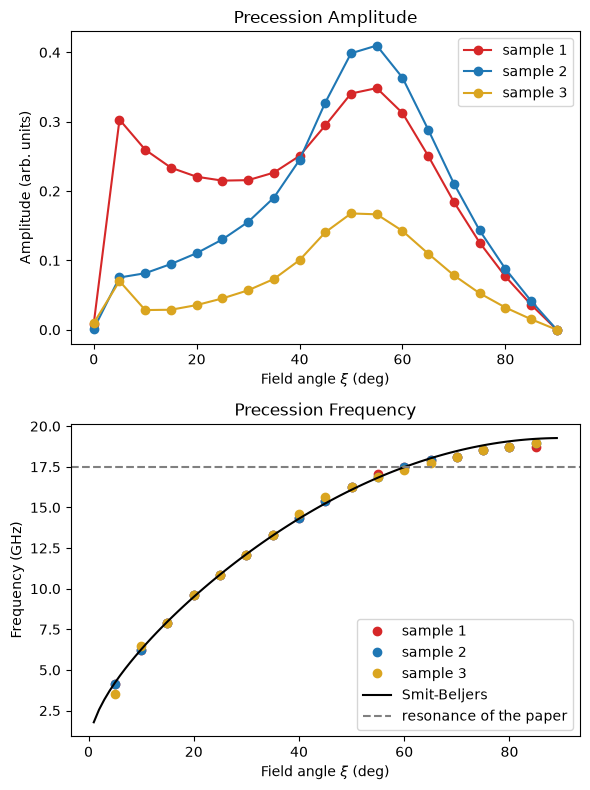

In [23]:
plt.figure(figsize=[6, 8])
plt.subplot(2, 1, 1)
for name in structures.keys():
    plt.plot(xi_scan, amplitudes[name], "o-", color=colors[name], label=name)
plt.xlabel(r"Field angle $\xi$ (deg)")
plt.ylabel("Amplitude (arb. units)")
plt.legend()
plt.title("Precession Amplitude")

plt.subplot(2, 1, 2)
for name in structures.keys():
    plt.plot(xi_scan[1:-1], frequencies[name][1:-1] * 1e-9, "o", color=colors[name], label=name)
plt.plot(np.degrees(xi_theory), f_smit_beljers * 1e-9, "k-", label="Smit-Beljers")
plt.axhline(17.5, color="gray", ls="--", label="resonance of the paper")
plt.xlabel(r"Field angle $\xi$ (deg)")
plt.ylabel("Frequency (GHz)")
plt.legend()
plt.title("Precession Frequency")

plt.tight_layout()
plt.show()

The frequency of all samples follows the Smit-Beljers formula and increases as the field is tilted towards the film plane.
The amplitude of sample 1 is largest for an out-of-plane field, where the rapid demagnetization and expansion of the Ni drive the precession.
For all samples, the amplitude is resonantly enhanced at a precession frequency of about 17 GHz, when the strain pulses echoing through the heterostructure periodically drive the precession.
This magneto-acoustic resonance is strongest for sample 2, whose spatially extended strain pulse launched by the Cu matches the phase of the precession, and much weaker for sample 3, whose narrow bipolar pulse launched by the Pt nearly cancels within a precession period.

These are the findings of {cite:t}`jarecki2024`, who observe the resonance at 17.5 GHz.
In our simulation it appears at a larger field angle than the 47° of the paper, as the simulated frequencies are slightly smaller than the measured ones at the same field angle.

### Precession for a Full Rotation of the Field

Fig. 1(c) of the paper shows $\Delta m_z$ of sample 1 for a full rotation of the external field.
We do not need to simulate all angles, since the LLG is invariant under rotations of the magnetization and the field together, and the shape anisotropy and the magnetoelastic field along $z$ are invariant under rotations by 180° around the $x$- and the $z$-axis.
The rotation around the $x$-axis maps the field angle $\xi$ to $180° - \xi$ and $m_z$ to $-m_z$, the rotation around the $z$-axis maps $\xi$ to $-\xi$ and keeps $m_z$.
Hence, the simulations from 0° to 90° above give the full rotation, which explains the fourfold symmetry observed in the paper.
For a field exactly along the film normal or in the film plane, the change of the effective field is parallel to the precession axis, so that $m_z$ does not oscillate.
Note that we keep the sign of $\Delta m_z$ of Fig. 2(c), i.e. $\Delta m_z < 0$ at $\xi = 5°$, while Fig. 1(c) of the paper shows the opposite sign.

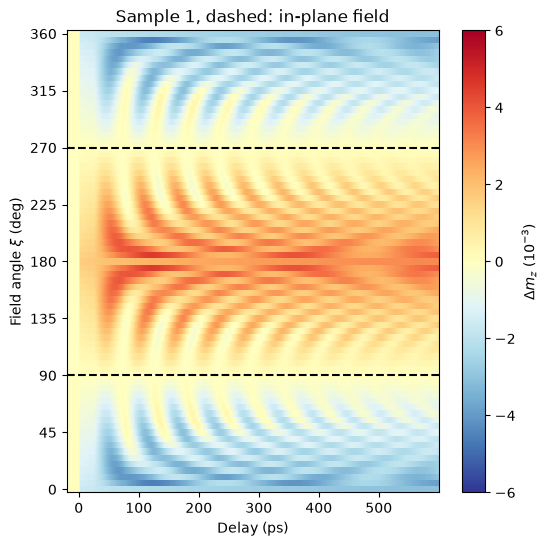

In [24]:
# 0° to 90° as simulated, 90° to 180° by the rotation around x,
# 180° to 360° by the rotation around z
delta_m_z = delta_m_z_maps["sample 1"]
xi_full = np.r_[xi_scan, 180 - xi_scan[::-1][1:], 180 + xi_scan[1:], 360 - xi_scan[::-1][1:]]
delta_m_z_full = np.r_[delta_m_z, -delta_m_z[::-1][1:], -delta_m_z[1:], delta_m_z[::-1][1:]]

plt.figure(figsize=[6, 6])
plt.pcolormesh(
    delays.to("ps").magnitude,
    xi_full,
    1e3 * delta_m_z_full,
    shading="auto",
    cmap="RdYlBu_r",
    vmin=-6,
    vmax=6,
)
plt.colorbar(label=r"$\Delta m_z$ ($10^{-3}$)")
plt.axhline(90, color="k", ls="--")
plt.axhline(270, color="k", ls="--")
plt.yticks(np.r_[0:361:45])
plt.xlabel("Delay (ps)")
plt.ylabel(r"Field angle $\xi$ (deg)")
plt.title("Sample 1, dashed: in-plane field")
plt.show()